# YAMNet 실녹음 평가와 임계값 재설정 (Raspberry Pi 마이크)

## 목표
**ESC-50(시중 음원)으로 정한 임계값은 Pi 마이크로 녹음한 소리에서 판단이 다르게 나온다.** 이 노트북은
1. 현재 임계값이 Pi 녹음에서 얼마나 틀리는지 보이고,
2. **Pi 녹음 기준으로 카테고리별 임계값(과 필요하면 클래스 구성)을 다시 정하고**,
3. 그 선택이 ESC-50 전체(2000클립)에서 **오경보를 늘리지 않는지 재검증**하고,
4. 보고서에 쓸 **그래프(PNG)와 최종 임계값 표**를 만든다.

## YAMNet 은 회귀 모델인가, 분류 모델인가?
**분류(classification) 모델이다.** 프레임(0.96초 창, 0.48초 간격)마다 AudioSet 521개 클래스 각각의 확률(0~1)을 낸다.
마지막 층이 softmax 가 아니라 sigmoid 라서 클래스끼리 독립이다(합이 1이 아님) → **다중 라벨 분류**.
모델은 *점수*만 내고 "이벤트다/아니다"는 우리 규칙(`core/event_rules.py`)의 임계값·다수결·조합이 정한다. 그래서 평가는 **이진 분류 지표**를 쓴다.

## 두 데이터의 역할 (중요)
| 데이터 | 역할 | 이유 |
|---|---|---|
| **Pi 녹음** (`dataset/`) | 임계값·클래스 구성을 **고르는 기준** | 제품이 실제로 듣는 소리와 같은 마이크·방 |
| **ESC-50 전체 2000클립** | 오경보 **방어선**(상한 제약) | Pi 에는 사건 없는 배경 녹음이 아직 없다. 임계값을 낮출 때 엉뚱한 소리에 울리지 않는지 ESC-50 의 다양한 소리로 대신 점검 |

선택 규칙: *ESC-50 음성 클립의 오경보율이 상한(`MAX_ESC_FPR`) 이하인 임계값 중에서 Pi 의 F-점수(위험 `높음`은 F2, 나머지 F1)가 최대인 값.*
클래스 구성 변경은 Pi 점수가 `MIN_GAIN` 이상 좋아질 때만 채택한다(잡음 쫓기 방지).

## 평가 방식
클립 단위 one-vs-rest 이진 분류. 카테고리 `c` 를 평가할 때 양성 = `c` 로 녹음한 클립, 음성 = 다른 카테고리 클립. 예측 = `c` 의 규칙이 그 클립에서 한 번이라도 트리거.

## 한계 (결과를 말할 때 항상 같이)
1. Pi 클립이 24개(카테고리당 양성 3~6개)뿐 → 신뢰구간이 매우 넓다.
2. 사건 없는 배경 녹음이 없다 → 시간당 오경보(FA/h)는 못 잰다. ESC-50 오경보율은 *대리 지표*다.
3. 같은 데이터로 고르고 같은 데이터로 점수를 내면 낙관적 → 교차검증(음원 단위: 처음 듣는 음원에 대한 성능)을 같이 보고, 확정 후에는 **새 세션·새 음원**으로 한 번 더 확인한다.

### [코드 설명] 환경 설정
- 지표(F1, MCC, AUC, 신뢰구간)는 sklearn 없이 numpy/scipy 로 직접 구현했다.
- 그림은 `yamnet/output/figures/*.png`(200dpi)로 저장되어 보고서에 바로 넣을 수 있다.
- `MAX_ESC_FPR`, `MIN_GAIN` 은 아래에서 바꿀 수 있는 선택 규칙의 파라미터다.

In [40]:
import os, sys, json, re, random, warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import soundfile as sf
from scipy.stats import rankdata
from IPython.display import display

SEED = 42
random.seed(SEED); np.random.seed(SEED)
plt.rcParams["font.family"] = "Malgun Gothic"      # Windows 한글 폰트
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 100

YAMNET_DIR = next(p for p in [Path.cwd(), Path.cwd() / "yamnet", Path.cwd().parent]
                  if (p / "core" / "event_rules.py").exists())
DATASET_DIR = YAMNET_DIR / "dataset"
OUTPUT_DIR = YAMNET_DIR / "output"
FIG_DIR = OUTPUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
ESC_AUDIO_DIR = YAMNET_DIR / "ESC-50" / "audio"
ESC_META_CSV = YAMNET_DIR / "ESC-50" / "meta" / "esc50.csv"
PI_CACHE = Path(os.environ.get("REALWORLD_CACHE", OUTPUT_DIR / "realworld_scores_cache.npz"))
ESC_CACHE = Path(os.environ.get("REALWORLD_ESC_CACHE", OUTPUT_DIR / "esc50_scores_cache.npz"))

sys.path.insert(0, str(YAMNET_DIR / "core"))
sys.path.insert(0, str(YAMNET_DIR / "verification"))
from category_map import get_category
from event_rules import CATEGORY_RULE_CONFIG, FRAME_HOP_SEC
from evaluate import POSITIVE_ESC50_CATEGORIES      # 홈톡 카테고리 -> 대응하는 ESC-50 카테고리 (기존 평가와 같은 매핑)

# ---- 선택 규칙 파라미터 --------------------------------------------------
MAX_ESC_FPR = 0.03     # ESC-50 음성 클립 중 이 비율 이하만 울리는 임계값만 후보로 인정
MIN_GAIN = 0.05        # 클래스 구성/규칙 변경은 Pi F-점수가 이만큼 좋아질 때만 채택
PI_FLOOR = 0.05        # 이 점수 미만이면 "YAMNet 이 못 알아본 클립"으로 센다
TH_FLOOR = 0.15        # 임계값 하한: 배경 소음 녹음이 없어 이보다 낮은 값은 오경보를 검증할 수 없다
ESC_TIE_TOL = 0.05     # Pi 점수가 같은 후보 중 ESC-50 Recall 이 최고보다 이만큼 넘게 떨어지는 값은 제외

def savefig(fig, name):
    fig.savefig(FIG_DIR / name, dpi=200, bbox_inches="tight")
    plt.show()
    print("그림 저장:", FIG_DIR / name)

print("yamnet 폴더:", YAMNET_DIR)

yamnet 폴더: c:\Users\WCL\Documents\GitHub\homecare\yamnet


## 1. Pi 녹음 불러오기

`record_dataset.py` 가 WAV 와 같은 이름의 `.json` 을 저장한다. 폴더 이름이 라벨이고, **끝 번호는 같은 이벤트의 서로 다른 음원(source) 번호**다
(`baby_cry2` → 카테고리 `baby_cry`, 음원 2). `animal_cat`/`animal_dog` 는 모두 `animal`.

**위치·음량 정보에 대해:** 음원마다 스피커를 좌/우 임의로 두고 음량도 바꿔 녹음했지만, JSON 의 `position` 은 모두 `center` 로 기록되어 있고 음량 값은 기록이 없다.
그래서 **이 데이터로는 위치별·음량별 분석을 할 수 없다.** 다음 녹음부터 `record_dataset.py ... left|right`, `--note "음량=작게"` 로 남기면 아래 분해 표가 자동으로 쓴다.

In [41]:
rows, skipped = [], []
for meta_path in sorted(DATASET_DIR.glob("*/*/*.json")):
    meta = json.loads(meta_path.read_text(encoding="utf-8"))
    folder = meta_path.parent.parent.name
    m = re.match(r"^(.*?)(\d*)$", folder)
    base, source = m.group(1), int(m.group(2) or 1)
    category = "animal" if base.startswith("animal") else base
    wav_path = meta_path.with_name(meta["wav"])
    if meta.get("status") != "complete" or meta.get("overflow_blocks", 0) != 0 or not wav_path.exists():
        skipped.append((folder, meta.get("status"), meta.get("overflow_blocks"))); continue
    rows.append(dict(clip_id=wav_path.stem, folder=folder, category=category,
                     subtype=base.split("_", 1)[1] if base.startswith("animal") else "",
                     source=source, position=meta.get("position", "center"),
                     note=meta.get("note", ""), seconds=meta.get("actual_seconds"), wav_path=str(wav_path)))

df = pd.DataFrame(rows).reset_index(drop=True)
print(f"사용 클립 {len(df)}개 / 제외 {len(skipped)}개", skipped if skipped else "")
display(df.pivot_table(index="category", columns="position", values="clip_id", aggfunc="count", fill_value=0))

사용 클립 24개 / 제외 0개 


position,center
category,
animal,6
baby_cry,3
door_visitor,6
fire_alarm_siren,3
glass_impact,3
scream_shout,3


### [코드 설명] 녹음 품질 + 음량 점검
- `win_max_dBFS` : 0.48초 구간 RMS 중 가장 큰 값(= 사건이 가장 크게 들린 순간). ESC-50 과 비교할 때 같은 방식으로 잰다(아래 그림 6).
- `clip_pct` : 포화(찌그러짐) 비율, `rms_dBFS` : 전체 평균 음량.

In [42]:
def loudest_window_dbfs(x, sr, win_sec=0.48):
    if x.ndim > 1: x = x.mean(axis=1)
    w = int(win_sec * sr); n = max(len(x) // w, 1)
    r = 20 * np.log10(np.sqrt((x[:n * w].reshape(n, -1) ** 2).mean(axis=1)) + 1e-9)
    return float(r.max())

def audio_stats(path):
    x, sr = sf.read(path)
    xm = x.mean(axis=1) if x.ndim > 1 else x
    return dict(sr=sr, peak=float(np.abs(xm).max()), rms_dBFS=20 * np.log10(float(np.sqrt(np.mean(xm ** 2))) + 1e-9),
                win_max_dBFS=loudest_window_dbfs(xm, sr), clip_pct=100 * float(np.mean(np.abs(xm) >= 0.99)))

df = df.join(pd.DataFrame([audio_stats(p) for p in df["wav_path"]]))
display(df[["clip_id", "category", "source", "position", "peak", "rms_dBFS", "win_max_dBFS", "clip_pct"]].round(2))
bad = df[(df.rms_dBFS < -60) | (df.clip_pct > 1.0) | (df.sr != 16000)]
print("점검 필요 클립:", "없음" if bad.empty else bad.clip_id.tolist())

,clip_id,category,source,position,peak,rms_dBFS,win_max_dBFS,clip_pct
0,animal_cat_center_20261018_112736_015573fe,animal,1,center,0.16,-36.74,-29.23,0.0
1,animal_cat2_center_20261018_112806_d787f243,animal,2,center,0.18,-40.28,-27.79,0.0
2,animal_cat3_center_20261018_112844_817656cd,animal,3,center,0.16,-40.18,-27.50,0.0
3,animal_center_20261018_112549_6b5cce83,animal,1,center,0.23,-38.57,-27.94,0.0
4,animal_dog2_center_20261018_112625_b4f614c5,animal,2,center,0.16,-39.42,-27.58,0.0
5,animal_dog3_center_20261018_112701_b8845ac3,animal,3,center,0.16,-41.39,-27.64,0.0
6,baby_cry_center_20261018_112913_9d19065f,baby_cry,1,center,0.18,-34.89,-26.30,0.0
7,baby_cry2_center_20261018_112943_a2baa81c,baby_cry,2,center,0.18,-40.64,-27.79,0.0
8,baby_cry3_center_20261018_113012_6cb306cd,baby_cry,3,center,0.18,-38.49,-27.43,0.0
9,door_visitor_center_20261018_113042_8e5554f1,door_visitor,1,center,0.18,-41.30,-27.92,0.0


점검 필요 클립: 없음


## 2. YAMNet 추론 (Pi 24클립 + ESC-50 2000클립)

### [코드 설명]
- 프레임 점수 행렬(프레임 × 521)을 `output/*.npz` 에 캐시한다. 처음 한 번만 TensorFlow/TF Hub 가 필요하고(ESC-50 2000클립은 몇 분 걸린다),
  이후에는 캐시만 읽는다. 새 녹음을 추가하면 새 클립만 추론한다.
- 전처리·추론은 운영 코드와 같은 `core/yamnet_core.py` 를 쓴다.

In [43]:
_MODEL = {}

def load_or_infer(items, cache_path):
    # items: [(key, wav_path), ...] -> {key: scores(frames, 521)}
    cache = {}
    if cache_path.exists():
        with np.load(cache_path, allow_pickle=False) as z:
            cache = {k: z[k] for k in z.files}
    missing = [(k, p) for k, p in items if k not in cache]
    if missing:
        from yamnet_core import load_yamnet, preprocess, infer
        if "m" not in _MODEL:
            _MODEL["m"] = load_yamnet()
        for i, (k, p) in enumerate(missing, 1):
            audio, sr = sf.read(p)
            cache[k] = infer(_MODEL["m"], preprocess(audio, sr))[0].astype(np.float32)
            if i % 100 == 0 or i == len(missing):
                print(f"  추론 {i}/{len(missing)}  ({cache_path.name})")
        np.savez_compressed(cache_path, **cache)
    return {k: cache[k] for k, _ in items}

PI_SCORES = load_or_infer(list(zip(df["clip_id"], df["wav_path"])), PI_CACHE)

esc_meta = pd.read_csv(ESC_META_CSV)
ESC_SCORES = load_or_infer([(f, str(ESC_AUDIO_DIR / f)) for f in esc_meta["filename"]], ESC_CACHE)
CLASS_NAMES_ALL = pd.read_csv(YAMNET_DIR / "core" / "yamnet_class_map.csv")["display_name"].tolist()
print("Pi 클립", len(PI_SCORES), "/ ESC-50 클립", len(ESC_SCORES), "/ scores 예시 shape", next(iter(PI_SCORES.values())).shape)

Pi 클립 24 / ESC-50 클립 2000 / scores 예시 shape (31, 521)


### [코드 설명] "분류 모델"임을 데이터로 확인 + 클립별 YAMNet 상위 클래스
프레임별 521개 점수의 합이 1 이 아니면 softmax 가 아니라 sigmoid(다중 라벨)다. 상위 클래스는 "YAMNet 이 그 소리를 무엇이라 불렀나"를 보여준다.

In [44]:
allv = np.concatenate([s.ravel() for s in PI_SCORES.values()])
rowsum = np.concatenate([s.sum(axis=1) for s in PI_SCORES.values()])
print(f"점수 범위 {allv.min():.4f} ~ {allv.max():.4f}")
print(f"프레임별 521개 점수 합: 평균 {rowsum.mean():.2f}, 최소 {rowsum.min():.2f}, 최대 {rowsum.max():.2f}  (softmax 라면 항상 1.00)")

def top_classes(scores, k=3, skip=(494,)):
    mx = scores.max(axis=0).copy()
    mx[list(skip)] = -1                       # Silence(494) 는 사건 소리가 아니라 빼고 본다
    idx = np.argsort(mx)[::-1][:k]
    return ", ".join(f"{CLASS_NAMES_ALL[i]}({mx[i]:.2f})" for i in idx)

tmp = df[["clip_id", "category", "source"]].copy()
tmp["YAMNet 상위 3 클래스 (Silence 제외)"] = [top_classes(PI_SCORES[c]) for c in df["clip_id"]]
pd.set_option("display.max_colwidth", 110); pd.set_option("display.width", 220)
display(tmp)

점수 범위 0.0000 ~ 1.0000
프레임별 521개 점수 합: 평균 1.35, 최소 0.27, 최대 5.61  (softmax 라면 항상 1.00)


,clip_id,category,source,YAMNet 상위 3 클래스 (Silence 제외)
0,animal_cat_center_20261018_112736_015573fe,animal,1,"Animal(1.00), Domestic animals, pets(1.00), Cat(0.99)"
1,animal_cat2_center_20261018_112806_d787f243,animal,2,"Animal(0.99), Domestic animals, pets(0.98), Cat(0.98)"
2,animal_cat3_center_20261018_112844_817656cd,animal,3,"Animal(1.00), Domestic animals, pets(1.00), Cat(0.99)"
3,animal_center_20261018_112549_6b5cce83,animal,1,"Animal(0.99), Domestic animals, pets(0.98), Dog(0.95)"
4,animal_dog2_center_20261018_112625_b4f614c5,animal,2,"Animal(1.00), Livestock, farm animals, working animals(0.97), Fowl(0.96)"
5,animal_dog3_center_20261018_112701_b8845ac3,animal,3,"Speech(1.00), Animal(0.97), Domestic animals, pets(0.94)"
6,baby_cry_center_20261018_112913_9d19065f,baby_cry,1,"Crying, sobbing(1.00), Baby cry, infant cry(0.98), Laughter(0.62)"
7,baby_cry2_center_20261018_112943_a2baa81c,baby_cry,2,"Crying, sobbing(1.00), Baby cry, infant cry(0.97), Whimper(0.58)"
8,baby_cry3_center_20261018_113012_6cb306cd,baby_cry,3,"Crying, sobbing(1.00), Baby cry, infant cry(0.98), Whimper(0.20)"
9,door_visitor_center_20261018_113042_8e5554f1,door_visitor,1,"Doorbell(0.99), Ding-dong(0.96), Ding(0.85)"


## 3. 평가 도구 준비

### 3-1. 평가 대상
`fire_alarm_siren, glass_impact, baby_cry, scream_shout, door_visitor, animal` 6개. (`door_security` 는 소리로 판단할 이벤트가 아니라 제외, `fall_suspect`·`long_silence` 등은 짧은 클립으로 평가 불가.)

### 3-2. 규칙 변형(variant)
Pi 에서 YAMNet 이 소리를 *다른 이름*으로 부른 경우(예: 사이렌을 "Telephone bell / Alarm clock" 으로)가 있어, 클래스 구성이나 규칙을 바꾼 후보를 만들어 비교한다.
변형은 `event_rules.py` 의 규칙 인자를 덮어쓰는 방식이라 코드 본체는 건드리지 않는다.

### 3-3. 트리거 점수 (속도 + 연속 점수)
규칙은 임계값이 높을수록 트리거되기 어렵다(단조). 그래서 클립마다 **"트리거되는 가장 높은 임계값"**(= `trigger score`)을 이분탐색으로 구하면
어떤 임계값에서의 예측이든 `trigger score >= 임계값` 한 줄로 알 수 있다(2000+24클립 × 수십 변형을 빠르게 처리). ROC-AUC 의 연속 점수로도 쓴다.

In [45]:
EVAL_CATS = ["fire_alarm_siren", "glass_impact", "baby_cry", "scream_shout", "door_visitor", "animal"]
TH_GRID = np.round(np.arange(0.01, 1.00, 0.01), 2)
DEFAULT_TH = {c: CATEGORY_RULE_CONFIG[c]["kwargs"]["threshold"] for c in EVAL_CATS}
HIGH_RISK = {c for c in EVAL_CATS if get_category(c).default_risk_level == "높음"}      # F2 로 고를 카테고리
METRIC = {c: ("F2" if c in HIGH_RISK else "F1") for c in EVAL_CATS}

def _ids(cat): return list(get_category(cat).class_ids)
def _fire(ids): return {"class_id_groups": [[i] for i in ids]}

# 변형 = 규칙 인자 덮어쓰기. 첫 번째("기본")가 현재 코드와 동일.
VARIANTS = {
    "fire_alarm_siren": {
        "기본": {},
        "+Alarm clock": _fire(_ids("fire_alarm_siren") + [389]),
        "+Alarm clock,Tel.bell": _fire(_ids("fire_alarm_siren") + [389, 384]),
        "+Alarm clock,Tel.bell,Telephone,Ringtone": _fire(_ids("fire_alarm_siren") + [389, 384, 383, 385]),
    },
    "glass_impact": {
        "기본": {},
        "두 그룹 중 하나만": {"min_groups": 1},
        "+Chink,clink / 하나만": {"class_id_groups": [[435, 434, 436], [437, 464]], "min_groups": 1},
    },
    "scream_shout": {
        "기본": {},
        "+Yell,Bellow,Children shouting": {"class_ids": _ids("scream_shout") + [9, 7, 10]},
    },
    "animal": {
        "기본": {},
        "+Animal,Domestic": {"class_ids": _ids("animal") + [67, 68]},
        "+Dog,Cat": {"class_ids": _ids("animal") + [69, 76]},
    },
    "baby_cry": {"기본": {}},
    "door_visitor": {"기본": {}},
}

def run_rule(cat, scores, threshold=None, overrides=None):
    cfg = CATEGORY_RULE_CONFIG[cat]
    kw = dict(cfg["kwargs"]); kw.update(overrides or {})
    if threshold is not None:
        kw["threshold"] = float(threshold)
    return cfg["fn"](scores, **kw)

def trigger_score(cat, scores, overrides=None):
    # TH_GRID[i] 에서 트리거되는 i 는 0..k-1 (단조) -> 이분탐색으로 k 를 찾는다
    lo, hi = 0, len(TH_GRID)
    while lo < hi:
        mid = (lo + hi) // 2
        if run_rule(cat, scores, TH_GRID[mid], overrides).triggered: lo = mid + 1
        else: hi = mid
    return float(TH_GRID[lo - 1]) if lo > 0 else 0.0

PI_IDS = df["clip_id"].tolist()
ESC_FILES = esc_meta["filename"].tolist()

SC = {}     # (카테고리, 변형) -> {"pi": 트리거 점수 배열, "esc": 트리거 점수 배열}
for cat in EVAL_CATS:
    for vname, ov in VARIANTS[cat].items():
        SC[(cat, vname)] = dict(pi=np.array([trigger_score(cat, PI_SCORES[c], ov) for c in PI_IDS]),
                                esc=np.array([trigger_score(cat, ESC_SCORES[f], ov) for f in ESC_FILES]))
print("트리거 점수 계산 완료:", len(SC), "개 (카테고리×변형)")

# 검증 1: 이분탐색 결과가 전체 임계값을 직접 돌린 결과와 같은가 (Pi 24클립, 기본 변형)
for cat in EVAL_CATS:
    for j in range(len(PI_IDS)):
        brute = [run_rule(cat, PI_SCORES[PI_IDS[j]], t).triggered for t in TH_GRID]
        assert (SC[(cat, "기본")]["pi"][j] >= TH_GRID) .tolist() == brute, (cat, PI_IDS[j])
# 검증 2: 현재 코드의 임계값 그대로 돌린 결과와 같은가
for cat in EVAL_CATS:
    direct = np.array([run_rule(cat, PI_SCORES[c]).triggered for c in PI_IDS])
    assert (direct == (SC[(cat, "기본")]["pi"] >= DEFAULT_TH[cat])).all(), cat
print("이분탐색 == 직접 실행 검증 통과")

TRUTH = {c: (df["category"] == c).to_numpy() for c in EVAL_CATS}
ESC_POS = {c: esc_meta["category"].isin(POSITIVE_ESC50_CATEGORIES.get(c, [])).to_numpy() for c in EVAL_CATS}
print("ESC-50 양성 클립 수:", {c: int(ESC_POS[c].sum()) for c in EVAL_CATS}, "(scream_shout 는 대응 ESC-50 카테고리 없음 → 오경보율만 봄)")

트리거 점수 계산 완료: 14 개 (카테고리×변형)
이분탐색 == 직접 실행 검증 통과
ESC-50 양성 클립 수: {'fire_alarm_siren': 80, 'glass_impact': 40, 'baby_cry': 40, 'scream_shout': 0, 'door_visitor': 40, 'animal': 440} (scream_shout 는 대응 ESC-50 카테고리 없음 → 오경보율만 봄)


### [코드 설명] 지표 함수
- **Precision**=TP/(TP+FP) (울린 것 중 진짜), **Recall**=TP/(TP+FN) (진짜 중 잡은 것 = 놓침 반대), **F1**=P·R 조화평균,
  **F2**=Recall 에 2배 가중(위험 이벤트는 놓침이 더 치명적), **MCC**=불균형에 강한 상관계수(−1~1),
  **Wilson 95% CI**=표본이 작을 때의 신뢰구간, **ROC-AUC**=임계값과 무관한 구분 능력, **Specificity**=TN/(TN+FP).

In [46]:
def wilson_ci(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; d = 1 + z * z / n
    center = (p + z * z / (2 * n)) / d
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return max(0.0, center - half), min(1.0, center + half)

def binary_metrics(y_true, y_pred):
    y = np.asarray(y_true, bool); p = np.asarray(y_pred, bool)
    tp = int((y & p).sum()); fp = int((~y & p).sum()); fn = int((y & ~p).sum()); tn = int((~y & ~p).sum())
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    spec = tn / (tn + fp) if tn + fp else 0.0
    fb = lambda b: (1 + b * b) * prec * rec / (b * b * prec + rec) if (b * b * prec + rec) > 0 else 0.0
    den = np.sqrt(float(tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    lo, hi = wilson_ci(tp, tp + fn)
    return dict(TP=tp, FP=fp, FN=fn, TN=tn, Precision=prec, Recall=rec, Specificity=spec, F1=fb(1), F2=fb(2),
                Accuracy=(tp + tn) / len(y), MCC=(tp * tn - fp * fn) / den if den > 0 else 0.0,
                Recall_CI_low=lo, Recall_CI_high=hi)

def roc_auc(y_true, score):
    y = np.asarray(y_true, bool); s = np.asarray(score, float)
    n1, n0 = int(y.sum()), int((~y).sum())
    if n1 == 0 or n0 == 0: return np.nan
    return (rankdata(s)[y].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

_m = binary_metrics([1, 1, 1, 0, 0, 0, 0, 0], [1, 1, 0, 1, 0, 0, 0, 0])
assert (_m["TP"], _m["FP"], _m["FN"], _m["TN"]) == (2, 1, 1, 4) and abs(_m["MCC"] - 0.4666666667) < 1e-6
assert abs(roc_auc([1, 1, 0, 0], [0.9, 0.8, 0.8, 0.1]) - 0.875) < 1e-9 and abs(wilson_ci(5, 10)[0] - 0.2366) < 1e-3
print("지표 함수 자체 검증 통과")

지표 함수 자체 검증 통과


## 4. 현재 임계값(ESC-50 기준으로 정한 값)의 Pi 성능 — "Before"

현재 코드의 임계값·클래스 구성 그대로 Pi 24클립에 적용한 결과다. 임계값을 이 데이터에 맞춰 바꾸지 않았다.
Accuracy 는 음성이 훨씬 많아 참고용이고, 주지표는 Recall(놓침)·Precision(오경보)·F1·MCC 다.

In [47]:
def table_from_pred(pred_map, th_map):
    out = []
    for c in EVAL_CATS:
        y = TRUTH[c]; r = binary_metrics(y, pred_map[c])
        r.update(category=c, threshold=th_map[c], n_pos=int(y.sum()), n_neg=int((~y).sum()))
        out.append(r)
    t = pd.DataFrame(out).set_index("category")
    return t[["threshold", "n_pos", "n_neg", "TP", "FP", "FN", "TN", "Precision", "Recall", "Recall_CI_low",
              "Recall_CI_high", "F1", "F2", "MCC", "Specificity", "Accuracy"]]

PRED_BEFORE = {c: SC[(c, "기본")]["pi"] >= DEFAULT_TH[c] for c in EVAL_CATS}
before = table_from_pred(PRED_BEFORE, DEFAULT_TH)
before["ROC_AUC"] = [roc_auc(TRUTH[c], SC[(c, "기본")]["pi"]) for c in EVAL_CATS]
display(before.round(3))
mb = before[["Precision", "Recall", "F1", "F2", "MCC"]].mean()
print("macro 평균:", {k: round(float(v), 3) for k, v in mb.items()}, "| micro:", dict(before[["TP", "FP", "FN", "TN"]].sum()))

,threshold,n_pos,n_neg,TP,FP,FN,TN,Precision,Recall,Recall_CI_low,Recall_CI_high,F1,F2,MCC,Specificity,Accuracy,ROC_AUC
category,,,,,,,,,,,,,,,,,
fire_alarm_siren,0.5,3,21,1,1,2,20,0.5,0.333,0.061,0.792,0.400,0.357,0.342,0.952,0.875,0.937
glass_impact,0.3,3,21,1,0,2,21,1.0,0.333,0.061,0.792,0.500,0.385,0.552,1.000,0.917,0.833
baby_cry,0.3,3,21,3,2,0,19,0.6,1.000,0.438,1.000,0.750,0.882,0.737,0.905,0.917,1.000
scream_shout,0.3,3,21,0,0,3,21,0.0,0.000,0.000,0.562,0.000,0.000,0.000,1.000,0.875,0.627
door_visitor,0.7,6,18,2,0,4,18,1.0,0.333,0.097,0.700,0.500,0.385,0.522,1.000,0.833,0.949
animal,0.3,6,18,5,0,1,18,1.0,0.833,0.436,0.970,0.909,0.862,0.889,1.000,0.958,0.986


macro 평균: {'Precision': 0.683, 'Recall': 0.472, 'F1': 0.51, 'F2': 0.478, 'MCC': 0.507} | micro: {'TP': 12, 'FP': 3, 'FN': 12, 'TN': 117}


## 5. 도메인 갭 — 같은 임계값이 ESC-50 에서는 어땠나

현재 임계값을 **ESC-50 전체**에 적용했을 때의 Recall(대응 카테고리 클립을 잡은 비율)과 오경보율을 Pi 결과와 나란히 둔다.
ESC-50 에서는 잘 잡히는데 Pi 에서는 못 잡는다면, 그 차이가 "시중 음원 ≠ 우리 마이크"라는 도메인 갭이다.

In [48]:
gap = []
for c in EVAL_CATS:
    s_esc = SC[(c, "기본")]["esc"]; t = DEFAULT_TH[c]
    gap.append(dict(category=c, threshold=t,
                    ESC50_Recall=float((s_esc[ESC_POS[c]] >= t).mean()) if ESC_POS[c].any() else np.nan,
                    ESC50_오경보율=float((s_esc[~ESC_POS[c]] >= t).mean()),
                    Pi_Recall=before.loc[c, "Recall"], Pi_Precision=before.loc[c, "Precision"]))
gap = pd.DataFrame(gap).set_index("category")
display(gap.round(3))

,threshold,ESC50_Recall,ESC50_오경보율,Pi_Recall,Pi_Precision
category,,,,,
fire_alarm_siren,0.5,0.762,0.015,0.333,0.5
glass_impact,0.3,0.825,0.003,0.333,1.0
baby_cry,0.3,0.850,0.002,1.000,0.6
scream_shout,0.3,NaN,0.001,0.000,0.0
door_visitor,0.7,0.625,0.004,0.333,1.0
animal,0.3,0.173,0.002,0.833,1.0


## 6. 임계값·클래스 구성 재설정 (Pi 기준 + ESC-50 오경보 제약)

### 방법
1. 모든 (카테고리, 변형)에 대해 임계값 0.01~0.99 를 훑는다. 각 임계값마다 **Pi 지표**(P/R/F1/F2)와 **ESC-50 오경보율**을 계산.
2. **ESC-50 오경보율 ≤ `MAX_ESC_FPR`** 인 임계값만 후보로 인정(너무 낮은 임계값 방지).
3. 임계값은 `TH_FLOOR`(0.15) 이상만 쓴다(배경 소음 녹음이 없어 더 낮은 값은 오경보를 검증할 수 없음).
   후보 중 Pi 의 F-점수(F2 또는 F1)가 최대인 값들 가운데, **ESC-50 Recall 이 최고보다 5%p 넘게 떨어지는 값은 빼고** 그 **가운데 값**을 고른다(꼭짓점 하나에 과적합하지 않게 평탄 구간 중앙).
4. 변형은 기본 대비 Pi F-점수가 `MIN_GAIN` 이상 오를 때만 채택. 비슷하면 기본(코드 변경 최소)을 유지한다.
5. 후보가 하나도 없으면(ESC-50 오경보 상한 초과) 오경보율이 가장 낮은 임계값을 쓰고 표시한다. Pi 양성을 하나도 못 잡으면 현재값을 유지하고 "보류"로 표시한다.

In [49]:
_ESC_CURVE = {}
def esc_curve(cat, vname):
    k = (cat, vname)
    if k not in _ESC_CURVE:
        s = SC[k]["esc"]; neg = s[~ESC_POS[cat]]; pos = s[ESC_POS[cat]]
        _ESC_CURVE[k] = (np.array([(neg >= t).mean() for t in TH_GRID]),
                         np.array([(pos >= t).mean() for t in TH_GRID]) if len(pos) else np.full(len(TH_GRID), np.nan))
    return _ESC_CURVE[k]

def sweep(cat, vname, mask=None):
    mk = np.ones(len(PI_IDS), bool) if mask is None else mask
    pi = SC[(cat, vname)]["pi"]; y = TRUTH[cat]
    fpr, rec = esc_curve(cat, vname)
    return pd.DataFrame([dict(threshold=t, **binary_metrics(y[mk], pi[mk] >= t), esc_fpr=fpr[j], esc_recall=rec[j])
                         for j, t in enumerate(TH_GRID)])

def select_threshold(cat, sw):
    # 반환: (임계값, 해당 F-점수, 비고)
    metric = METRIC[cat]; note = ""
    pool = sw[sw.threshold >= TH_FLOOR]
    ok = pool[pool.esc_fpr <= MAX_ESC_FPR]
    if ok.empty:
        ok = pool[np.isclose(pool.esc_fpr, pool.esc_fpr.min())]; note = "ESC-50 오경보 상한 초과"
    top = float(ok[metric].max())
    if top <= 0:
        return DEFAULT_TH[cat], 0.0, "Pi 양성 검출 불가→현재값 유지"
    tied = ok[np.isclose(ok[metric], top)]
    if tied.esc_recall.notna().any():                               # ESC-50 양성이 있는 카테고리: 공개 음원을 놓치는 값은 제외
        tied = tied[tied.esc_recall >= tied.esc_recall.max() - ESC_TIE_TOL]
    cands = tied.threshold.to_numpy()
    th = float(cands[np.argmin(np.abs(cands - np.median(cands)))])
    return th, top, note

SW, SEL = {}, {}
for (cat, vname) in SC:
    SW[(cat, vname)] = sweep(cat, vname)
    SEL[(cat, vname)] = select_threshold(cat, SW[(cat, vname)])

# 변형 비교표
vrows = []
for (cat, vname), (th, obj, note) in SEL.items():
    r = SW[(cat, vname)].set_index("threshold").loc[th]
    vrows.append(dict(category=cat, variant=vname, metric=METRIC[cat], best_threshold=th, Pi_score=obj,
                      Pi_Recall=r.Recall, Pi_Precision=r.Precision, ESC50_오경보율=r.esc_fpr, ESC50_Recall=r.esc_recall,
                      Pi_AUC=roc_auc(TRUTH[cat], SC[(cat, vname)]["pi"]), note=note))
variants_df = pd.DataFrame(vrows)

# 변형 채택
FINAL = {}
for cat in EVAL_CATS:
    names = list(VARIANTS[cat])
    base_obj = SEL[(cat, names[0])][1]
    best = max(names, key=lambda n: (SEL[(cat, n)][1], -names.index(n)))          # 동점이면 앞(기본에 가까운) 쪽
    chosen = best if SEL[(cat, best)][1] >= base_obj + MIN_GAIN else names[0]
    variants_df.loc[(variants_df.category == cat) & (variants_df.variant == chosen), "채택"] = "★"
    th, obj, note = SEL[(cat, chosen)]
    FINAL[cat] = dict(variant=chosen, threshold=th, score=obj, note=note)

display(variants_df.fillna("").round(3).set_index(["category", "variant"]))
print("\n채택:", {c: (v["variant"], v["threshold"]) for c, v in FINAL.items()})

metric  best_threshold  Pi_score  Pi_Recall  Pi_Precision  ESC50_오경보율 ESC50_Recall  Pi_AUC                note 채택
category         variant                                                                                                                                                   
fire_alarm_siren 기본                                           F2            0.42     0.667      0.667         0.667       0.020          0.8   0.937                      ★
                 +Alarm clock                                 F2            0.42     0.625      0.667         0.500       0.022         0.95   0.889                       
                 +Alarm clock,Tel.bell                        F2            0.42     0.625      0.667         0.500       0.022         0.95   0.889                       
                 +Alarm clock,Tel.bell,Telephone,Ringtone     F2            0.60     0.667      0.667         0.667       0.011         0.95   0.905                       
glass_impact     기본                                           F2            0.24     0.385      0.333         1.000       0.006        0.825   0.833                       
                 두 그룹 중 하나만                                   F2            0.39     0.714      0.667         1.000       0.017        0.925   0.952                      ★
                 +Chink,clink / 하나만                           F2            0.39     0.714      0.667         1.000       0.018        0.925   0.952                       
baby_cry         기본                                           F1            0.78     1.000      1.000         1.000       0.001        0.575   1.000                      ★
scream_shout     기본                                           F1            0.30     0.000      0.000         0.000       0.001                0.627  Pi 양성 검출 불가→현재값 유지  ★
                 +Yell,Bellow,Children shouting               F1            0.30     0.000      0.000         0.000       0.001                0.627  Pi 양성 검출 불가→현재값 유지   
door_visitor     기본                                           F1            0.18     0.727      0.667         0.800       0.019        0.875   0.949                      ★
animal           기본                                           F1            0.33     0.909      0.833         1.000       0.001     0.172727   0.986                       
                 +Animal,Domestic                             F1            0.78     1.000      1.000         1.000       0.019         0.85   1.000                      ★
                 +Dog,Cat                                     F1            0.43     1.000      1.000         1.000       0.019     0.231818   1.000


채택: {'fire_alarm_siren': ('기본', 0.42), 'glass_impact': ('두 그룹 중 하나만', 0.39), 'baby_cry': ('기본', 0.78), 'scream_shout': ('기본', 0.3), 'door_visitor': ('기본', 0.18), 'animal': ('+Animal,Domestic', 0.78)}


## 7. 최종 선택 — Before / After 비교표

- **Before** = 현재 코드(임계값·기본 클래스), **After** = 6번에서 고른 변형 + 임계값. 둘 다 같은 Pi 24클립에 적용한 결과다.
- ⚠ After 의 Pi 점수는 같은 데이터로 골랐으므로 *낙관적*이다. 신뢰할 수준은 8번 교차검증과 `ESC50_오경보율` 로 판단하고, 확정 후 새 세션으로 확인한다.
- `조치` 열: Pi Recall ≥ 0.8 이면 **적용 가능**, 0.5~0.8 이면 **조건부**(녹음 보강 후 재확인), 그 미만이거나 Pi 양성을 못 잡으면 **보류**(임계값으로 해결 안 됨).

In [50]:
PRED_AFTER, SC_AFTER = {}, {}
for c in EVAL_CATS:
    SC_AFTER[c] = SC[(c, FINAL[c]["variant"])]
    PRED_AFTER[c] = SC_AFTER[c]["pi"] >= FINAL[c]["threshold"]
TH_AFTER = {c: FINAL[c]["threshold"] for c in EVAL_CATS}
after = table_from_pred(PRED_AFTER, TH_AFTER)
after["ROC_AUC"] = [roc_auc(TRUTH[c], SC_AFTER[c]["pi"]) for c in EVAL_CATS]

def action(r, note):
    if "보류" in note or "유지" in note: return "보류"
    if r.Recall >= 0.8: return "적용 가능"
    if r.Recall >= 0.5: return "조건부"
    return "보류"

final_rows = []
for c in EVAL_CATS:
    b, a = before.loc[c], after.loc[c]
    v = FINAL[c]["variant"]; th = FINAL[c]["threshold"]
    esc_fpr = esc_curve(c, v)[0][int(np.argmin(np.abs(TH_GRID - th)))]
    esc_rec = esc_curve(c, v)[1][int(np.argmin(np.abs(TH_GRID - th)))]
    n_undetect = int((SC_AFTER[c]["pi"][TRUTH[c]] < PI_FLOOR).sum())
    final_rows.append({
        "카테고리": c, "위험도": get_category(c).default_risk_level, "선택 기준": METRIC[c],
        "클래스/규칙": v, "임계값 Before": DEFAULT_TH[c], "임계값 After": th,
        "Recall Before": b.Recall, "Recall After": a.Recall,
        "Recall 95%CI After": f"{a.Recall_CI_low:.2f}~{a.Recall_CI_high:.2f}",
        "Precision Before": b.Precision, "Precision After": a.Precision,
        "F1 Before": b.F1, "F1 After": a.F1,
        "Pi 놓침 Before→After": f"{int(b.FN)}→{int(a.FN)}", "Pi 오경보 Before→After": f"{int(b.FP)}→{int(a.FP)}",
        "Pi 검출불가 양성": f"{n_undetect}/{int(TRUTH[c].sum())}",
        "ESC-50 오경보율 After": esc_fpr, "ESC-50 Recall After": esc_rec,
        "조치": action(a, FINAL[c]["note"]), "비고": FINAL[c]["note"]})
final_df = pd.DataFrame(final_rows).set_index("카테고리")
display(final_df.round(3).T)

카테고리,fire_alarm_siren,glass_impact,baby_cry,scream_shout,door_visitor,animal
위험도,높음,높음,중간,중간,낮음,중간
선택 기준,F2,F2,F1,F1,F1,F1
클래스/규칙,기본,두 그룹 중 하나만,기본,기본,기본,"+Animal,Domestic"
임계값 Before,0.5,0.3,0.3,0.3,0.7,0.3
임계값 After,0.42,0.39,0.78,0.3,0.18,0.78
Recall Before,0.333,0.333,1.0,0.0,0.333,0.833
Recall After,0.667,0.667,1.0,0.0,0.667,1.0
Recall 95%CI After,0.21~0.94,0.21~0.94,0.44~1.00,0.00~0.56,0.30~0.90,0.61~1.00
Precision Before,0.5,1.0,0.6,0.0,1.0,1.0
Precision After,0.667,1.0,1.0,0.0,0.8,1.0


## 8. 음원 단위 교차검증 (Leave-One-Source-Out) — 처음 듣는 음원에서의 성능

7번 점수는 같은 데이터로 골라서 낙관적이다. 여기서는 음원 번호(1,2,3…)를 하나씩 통째로 빼고, **나머지 음원으로 같은 선택 절차**(ESC-50 제약 포함)를 다시 돌려 임계값을 고른 뒤
빠진 음원을 예측한다. 모든 음원의 예측을 합친 지표가 **"튜닝에 한 번도 안 쓴 음원"에 대한 성능**이다 — 새 음원이 와도 임계값이 통하는지를 보는 가장 솔직한 수치다.
⚠ 같은 날·같은 장소·같은 마이크이고 음원 수가 카테고리당 3~5개뿐이라 여전히 약식이다. 새 세션·새 음원이 최종 검증이다.

In [51]:
GROUPS = df["source"].to_numpy()
cv_pred, cv_th = {}, {}
for c in EVAL_CATS:
    v = FINAL[c]["variant"]; pred = np.zeros(len(PI_IDS), bool); used = {}
    for g in sorted(set(GROUPS)):
        train = GROUPS != g; held = GROUPS == g
        th, _, _ = select_threshold(c, sweep(c, v, mask=train))
        pred[held] = SC[(c, v)]["pi"][held] >= th; used[g] = th
    cv_pred[c], cv_th[c] = pred, used

cvt = table_from_pred(cv_pred, {c: np.nan for c in EVAL_CATS})
cmp_cv = pd.DataFrame({
    "F1 Before(현재)": before["F1"], "F1 After(자체평가)": after["F1"], "F1 교차검증": cvt["F1"],
    "Recall Before": before["Recall"], "Recall 교차검증": cvt["Recall"],
    "Precision Before": before["Precision"], "Precision 교차검증": cvt["Precision"]})
display(cmp_cv.round(3))
print("교차검증 macro F1:", round(float(cvt["F1"].mean()), 3), "| Before macro F1:", round(float(before["F1"].mean()), 3),
      "| After(자체) macro F1:", round(float(after["F1"].mean()), 3))
print("\n음원별 선택된 임계값 (그 음원을 뺀 선택):")
display(pd.DataFrame(cv_th).T.round(2))

,F1 Before(현재),F1 After(자체평가),F1 교차검증,Recall Before,Recall 교차검증,Precision Before,Precision 교차검증
category,,,,,,,
fire_alarm_siren,0.400,0.667,0.400,0.333,0.333,0.5,0.50
glass_impact,0.500,0.800,0.800,0.333,0.667,1.0,1.00
baby_cry,0.750,1.000,0.857,1.000,1.000,0.6,0.75
scream_shout,0.000,0.000,0.000,0.000,0.000,0.0,0.00
door_visitor,0.500,0.727,0.600,0.333,0.500,1.0,0.75
animal,0.909,1.000,1.000,0.833,1.000,1.0,1.00


교차검증 macro F1: 0.61 | Before macro F1: 0.51 | After(자체) macro F1: 0.699

음원별 선택된 임계값 (그 음원을 뺀 선택):


,1,2,3,4,5
fire_alarm_siren,0.58,0.42,0.42,0.42,0.42
glass_impact,0.39,0.39,0.39,0.39,0.39
baby_cry,0.41,0.78,0.78,0.78,0.78
scream_shout,0.30,0.30,0.30,0.30,0.30
door_visitor,0.18,0.51,0.18,0.18,0.18
animal,0.78,0.78,0.78,0.78,0.78


## 9. 보고서용 그래프

모든 그림은 `yamnet/output/figures/` 에 PNG 로 저장된다. 색: 파랑=After(새 값), 빨강 점선=Before(현재 값), 회색=음성/ESC-50.

### 그림 1. 임계값 튜닝 곡선
카테고리별로 임계값을 바꿀 때 Pi 의 Precision/Recall/F1/F2 와 ESC-50 오경보율(회색 점선, 오른쪽 축)이 어떻게 변하는지 보여준다.
**붉은 음영 = ESC-50 오경보율이 상한을 넘어 후보에서 제외된 영역**, 빨강 점선 = 현재 값, 파랑 실선 = 선택한 값.

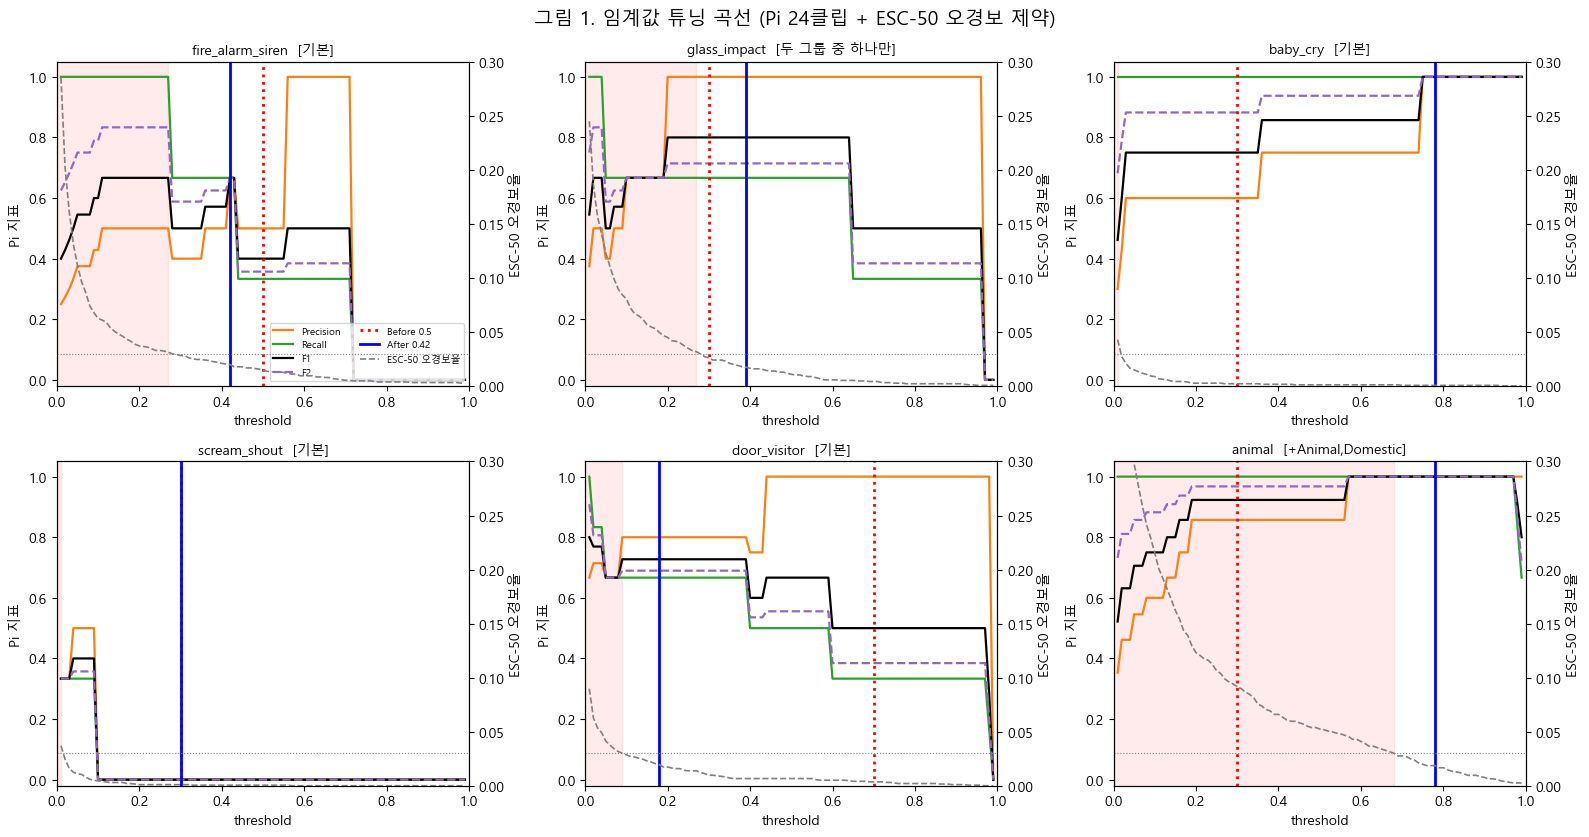

그림 저장: c:\Users\WCL\Documents\GitHub\homecare\yamnet\output\figures\fig1_threshold_tuning_curves.png


In [52]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
for ax, c in zip(axes.ravel(), EVAL_CATS):
    v = FINAL[c]["variant"]; sw = SW[(c, v)]
    for m, st, col in [("Precision", "-", "tab:orange"), ("Recall", "-", "tab:green"), ("F1", "-", "black"), ("F2", "--", "tab:purple")]:
        ax.plot(sw.threshold, sw[m], st, color=col, label=m, lw=1.6)
    bad = sw.esc_fpr > MAX_ESC_FPR
    if bad.any():
        ax.axvspan(0, sw.threshold[bad].max(), color="red", alpha=0.08)
    ax.axvline(DEFAULT_TH[c], color="red", ls=":", lw=2, label=f"Before {DEFAULT_TH[c]}")
    ax.axvline(FINAL[c]["threshold"], color="blue", lw=2, label=f"After {FINAL[c]['threshold']}")
    ax.set_ylim(-0.02, 1.05); ax.set_xlim(0, 1); ax.set_xlabel("threshold"); ax.set_ylabel("Pi 지표")
    ax2 = ax.twinx(); ax2.plot(sw.threshold, sw.esc_fpr, color="gray", ls="--", lw=1.2, label="ESC-50 오경보율")
    ax2.axhline(MAX_ESC_FPR, color="gray", ls=":", lw=0.8); ax2.set_ylim(0, 0.3); ax2.set_ylabel("ESC-50 오경보율")
    ax.set_title(f"{c}  [{v}]", fontsize=10)
    if c == EVAL_CATS[0]:
        h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
        ax.legend(h1 + h2, l1 + l2, fontsize=7, ncol=2, loc="lower right")
fig.suptitle("그림 1. 임계값 튜닝 곡선 (Pi 24클립 + ESC-50 오경보 제약)", fontsize=14)
fig.tight_layout(); savefig(fig, "fig1_threshold_tuning_curves.png")

### 그림 2. Before / After — Precision · Recall · F1
막대 = Before(회색, 현재 값) vs After(파랑, 선택 값). Recall After 의 검은 선 = Wilson 95% 신뢰구간(표본이 작아 넓다).

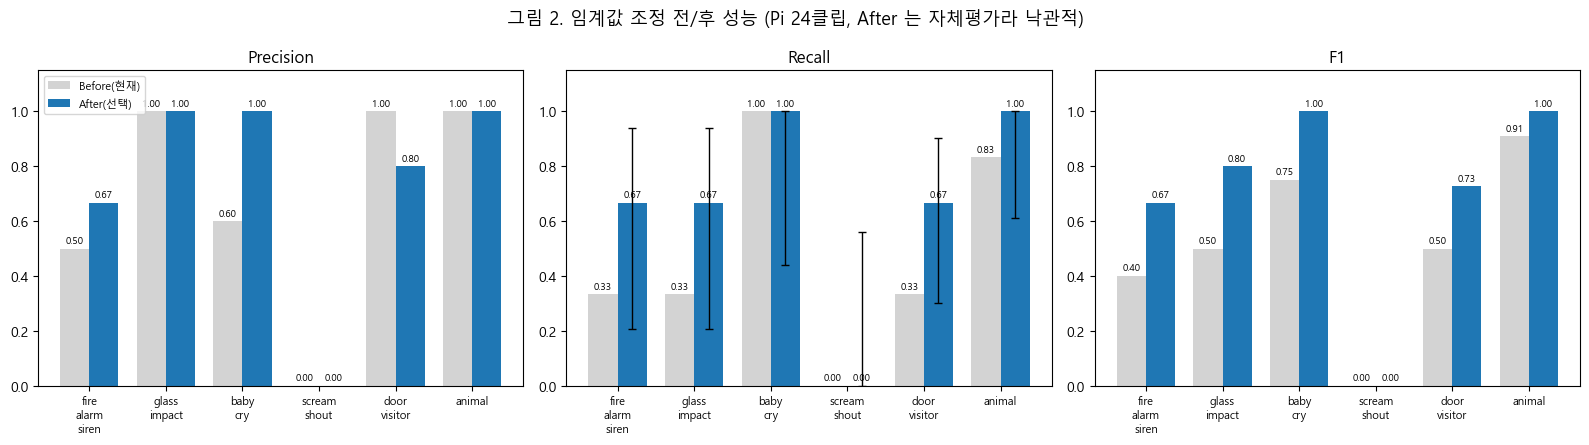

그림 저장: c:\Users\WCL\Documents\GitHub\homecare\yamnet\output\figures\fig2_before_after_prf.png


In [53]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
x = np.arange(len(EVAL_CATS)); w = 0.38
for ax, m in zip(axes, ["Precision", "Recall", "F1"]):
    bv = [before.loc[c, m] for c in EVAL_CATS]; av = [after.loc[c, m] for c in EVAL_CATS]
    ax.bar(x - w / 2, bv, w, color="lightgray", label="Before(현재)")
    ax.bar(x + w / 2, av, w, color="tab:blue", label="After(선택)")
    if m == "Recall":
        lo = [max(0.0, after.loc[c, "Recall"] - after.loc[c, "Recall_CI_low"]) for c in EVAL_CATS]
        hi = [max(0.0, after.loc[c, "Recall_CI_high"] - after.loc[c, "Recall"]) for c in EVAL_CATS]
        ax.errorbar(x + w / 2, av, yerr=[lo, hi], fmt="none", ecolor="black", capsize=3, lw=1)
    for i, (b_, a_) in enumerate(zip(bv, av)):
        ax.text(i - w / 2, b_ + 0.02, f"{b_:.2f}", ha="center", fontsize=7); ax.text(i + w / 2, a_ + 0.02, f"{a_:.2f}", ha="center", fontsize=7)
    ax.set_xticks(x); ax.set_xticklabels([c.replace("_", "\n") for c in EVAL_CATS], fontsize=8)
    ax.set_ylim(0, 1.15); ax.set_title(m)
    if m == "Precision": ax.legend(fontsize=8)
fig.suptitle("그림 2. 임계값 조정 전/후 성능 (Pi 24클립, After 는 자체평가라 낙관적)", fontsize=13)
fig.tight_layout(); savefig(fig, "fig2_before_after_prf.png")

### 그림 3. ROC 곡선 / Precision–Recall 곡선 (After 변형 기준)
**ROC**: 가로 FPR(오경보율), 세로 TPR(Recall). 왼쪽 위에 붙을수록, AUC 가 1 에 가까울수록 *임계값과 무관하게* 두 소리를 잘 구분한다.
**PR**: 가로 Recall, 세로 Precision. 양성이 적고 음성이 많은 상황에서 더 정직한 그림이다.

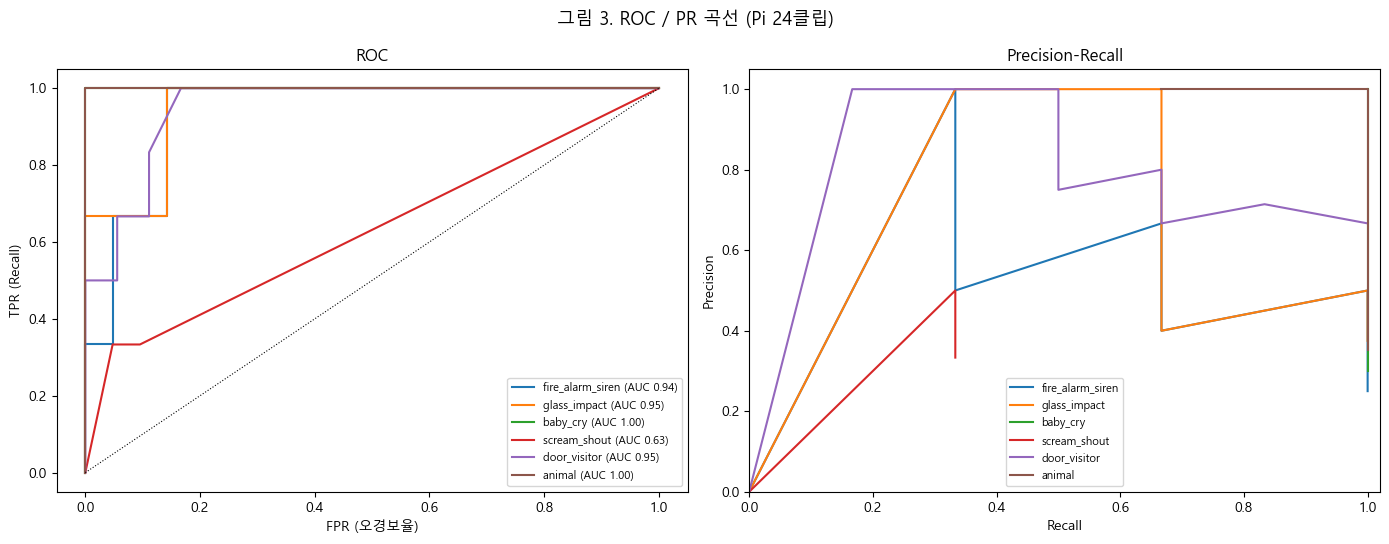

그림 저장: c:\Users\WCL\Documents\GitHub\homecare\yamnet\output\figures\fig3_roc_pr.png


In [54]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5.5))
cols = plt.cm.tab10.colors
for k, c in enumerate(EVAL_CATS):
    sw = SW[(c, FINAL[c]["variant"])]
    fpr = 1 - sw.Specificity.to_numpy(); tpr = sw.Recall.to_numpy(); prec = sw.Precision.to_numpy()
    a1.plot(np.r_[1, fpr, 0], np.r_[1, tpr, 0], "-", color=cols[k], label=f"{c} (AUC {after.loc[c, 'ROC_AUC']:.2f})")
    a2.plot(tpr, prec, "-", color=cols[k], label=c)
a1.plot([0, 1], [0, 1], "k:", lw=0.8); a1.set_xlabel("FPR (오경보율)"); a1.set_ylabel("TPR (Recall)"); a1.set_title("ROC"); a1.legend(fontsize=8)
a2.set_xlabel("Recall"); a2.set_ylabel("Precision"); a2.set_title("Precision-Recall"); a2.set_xlim(0, 1.02); a2.set_ylim(0, 1.05); a2.legend(fontsize=8)
fig.suptitle("그림 3. ROC / PR 곡선 (Pi 24클립)", fontsize=13)
fig.tight_layout(); savefig(fig, "fig3_roc_pr.png")

### 그림 4. 혼동 행렬 — 어느 소리가 어느 규칙을 울리나 (Before vs After)
행 = 실제 녹음 카테고리, 열 = 울린 규칙, 칸 = (울린 클립 수/그 행의 클립 수). **대각선이 진할수록 정상**, 대각선 밖이 진하면 오경보다.

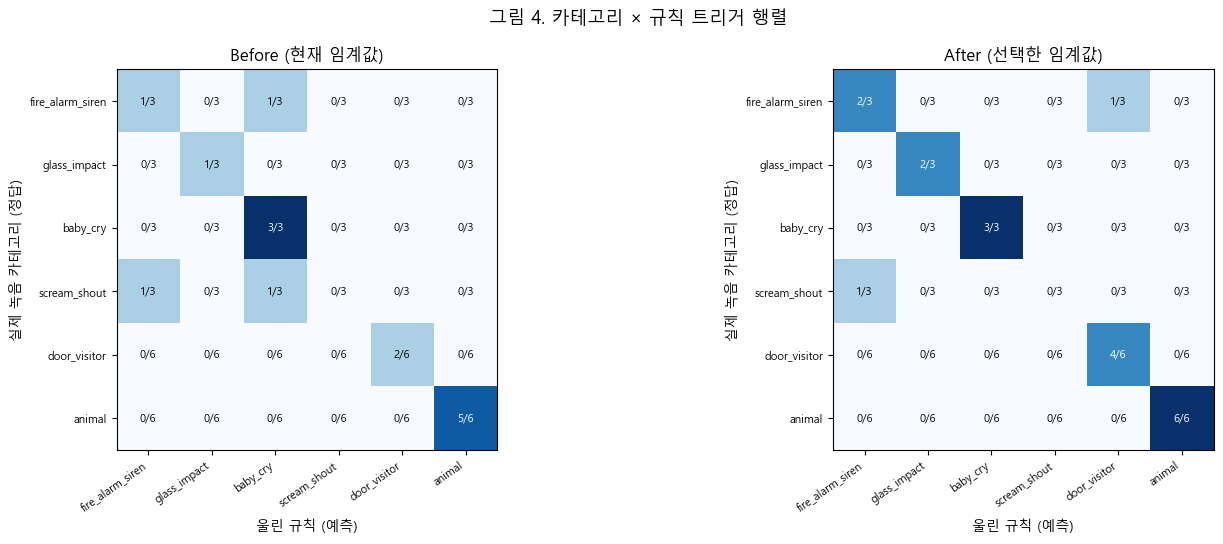

그림 저장: c:\Users\WCL\Documents\GitHub\homecare\yamnet\output\figures\fig4_trigger_matrix_before_after.png


In [55]:
def trigger_matrix(pred_map):
    M = np.zeros((len(EVAL_CATS), len(EVAL_CATS))); T = [[""] * len(EVAL_CATS) for _ in EVAL_CATS]
    for i, rc in enumerate(EVAL_CATS):
        mask = TRUTH[rc]
        for j, cc in enumerate(EVAL_CATS):
            k = int(pred_map[cc][mask].sum()); n = int(mask.sum()); M[i, j] = k / n; T[i][j] = f"{k}/{n}"
    return M, T

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, (title, pm) in zip(axes, [("Before (현재 임계값)", PRED_BEFORE), ("After (선택한 임계값)", PRED_AFTER)]):
    M, T = trigger_matrix(pm)
    im = ax.imshow(M, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(EVAL_CATS))); ax.set_xticklabels(EVAL_CATS, rotation=35, ha="right", fontsize=8)
    ax.set_yticks(range(len(EVAL_CATS))); ax.set_yticklabels(EVAL_CATS, fontsize=8)
    for i in range(len(EVAL_CATS)):
        for j in range(len(EVAL_CATS)):
            ax.text(j, i, T[i][j], ha="center", va="center", color="white" if M[i, j] > 0.6 else "black", fontsize=8)
    ax.set_xlabel("울린 규칙 (예측)"); ax.set_ylabel("실제 녹음 카테고리 (정답)"); ax.set_title(title)
fig.suptitle("그림 4. 카테고리 × 규칙 트리거 행렬", fontsize=13)
fig.tight_layout(); savefig(fig, "fig4_trigger_matrix_before_after.png")

### 그림 5. 점수 분포 — Pi 양성/음성과 ESC-50 비교
각 점은 클립 하나의 *트리거 점수*(규칙이 울리는 가장 높은 임계값). 초록=Pi 양성, 회색=Pi 음성, 파랑 속빈 원=ESC-50 양성, 연회색=ESC-50 음성(무작위 150개).
**ESC-50 양성(파랑)이 Pi 양성(초록)보다 위에 몰려 있으면** ESC-50 으로 정한 임계값이 Pi 에서는 너무 높다는 시각적 증거다.

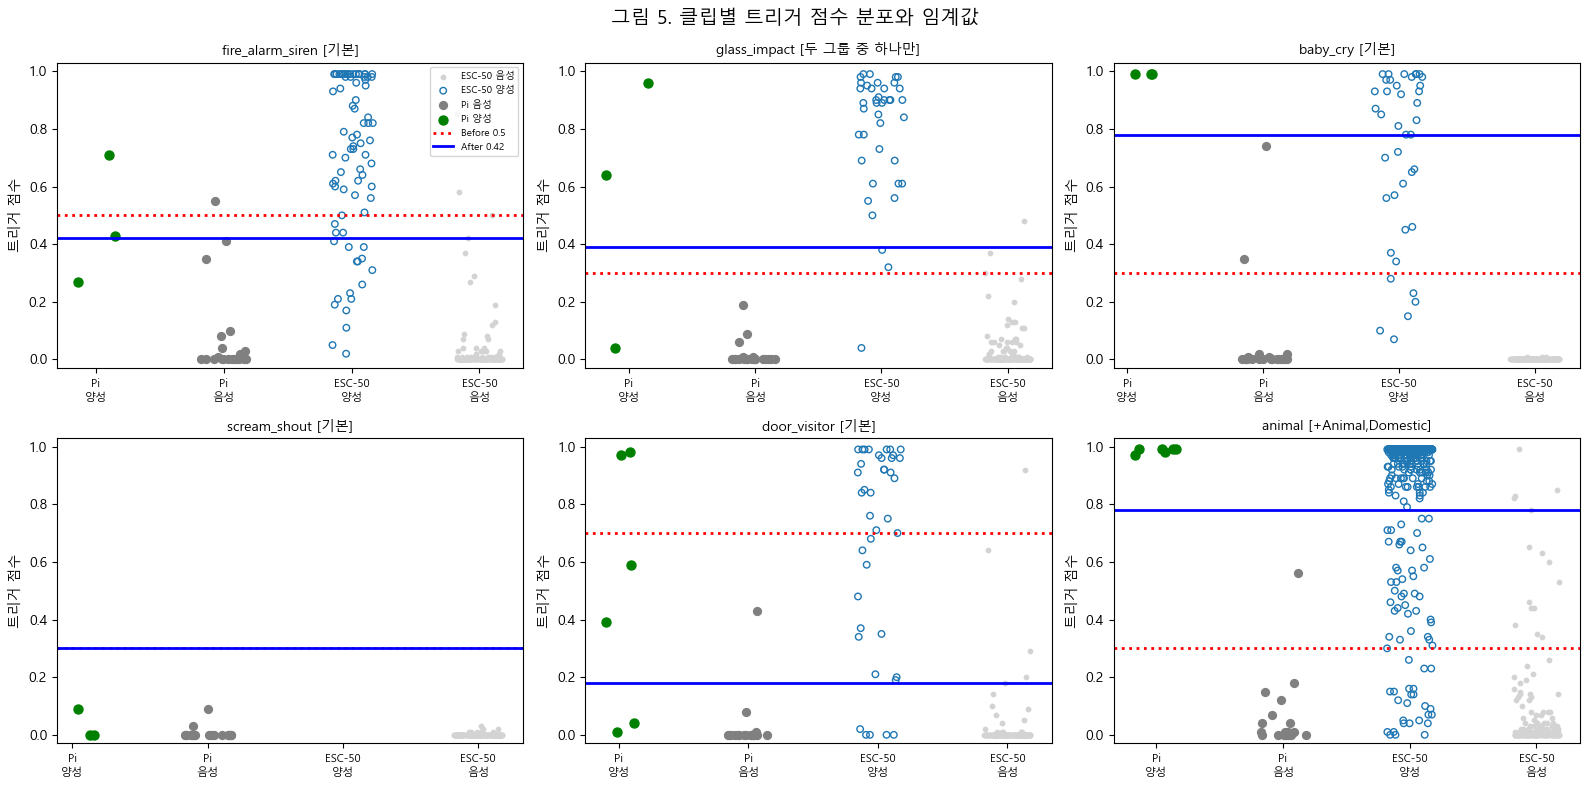

그림 저장: c:\Users\WCL\Documents\GitHub\homecare\yamnet\output\figures\fig5_score_distribution.png


In [56]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
rng = np.random.default_rng(SEED)
for ax, c in zip(axes.ravel(), EVAL_CATS):
    sc = SC_AFTER[c]["pi"]; esc = SC_AFTER[c]["esc"]; y = TRUTH[c]; ep = ESC_POS[c]
    jit = lambda n, x0: rng.uniform(-0.18, 0.18, n) + x0
    neg_idx = rng.choice(np.where(~ep)[0], size=min(150, int((~ep).sum())), replace=False)
    ax.scatter(jit(len(neg_idx), 3), esc[neg_idx], s=10, c="lightgray", label="ESC-50 음성")
    if ep.any():
        ax.scatter(jit(int(ep.sum()), 2), esc[ep], s=22, facecolors="none", edgecolors="tab:blue", label="ESC-50 양성")
    ax.scatter(jit(int((~y).sum()), 1), sc[~y], s=32, c="gray", label="Pi 음성")
    ax.scatter(jit(int(y.sum()), 0), sc[y], s=42, c="green", label="Pi 양성")
    ax.axhline(DEFAULT_TH[c], color="red", ls=":", lw=2, label=f"Before {DEFAULT_TH[c]}")
    ax.axhline(FINAL[c]["threshold"], color="blue", lw=2, label=f"After {FINAL[c]['threshold']}")
    ax.set_xticks([0, 1, 2, 3]); ax.set_xticklabels(["Pi\n양성", "Pi\n음성", "ESC-50\n양성", "ESC-50\n음성"], fontsize=8)
    ax.set_ylim(-0.03, 1.03); ax.set_ylabel("트리거 점수"); ax.set_title(f"{c} [{FINAL[c]['variant']}]", fontsize=10)
    if c == EVAL_CATS[0]: ax.legend(fontsize=7, loc="upper right")
fig.suptitle("그림 5. 클립별 트리거 점수 분포와 임계값", fontsize=14)
fig.tight_layout(); savefig(fig, "fig5_score_distribution.png")

### 그림 6. 음량 갭 — Pi 녹음 vs ESC-50
각 클립에서 가장 크게 들린 0.48초 구간의 음량(dBFS, 0에 가까울수록 큼). ESC-50 은 같은 카테고리에 해당하는 양성 클립만 쓴다.
Pi 녹음이 전반적으로 더 작다면 YAMNet 점수도 낮아져, ESC-50 으로 정한 임계값이 Pi 에서 높게 느껴지는 원인 후보가 된다(원인 확정은 같은 음원을 다른 음량으로 비교 녹음해야 함).

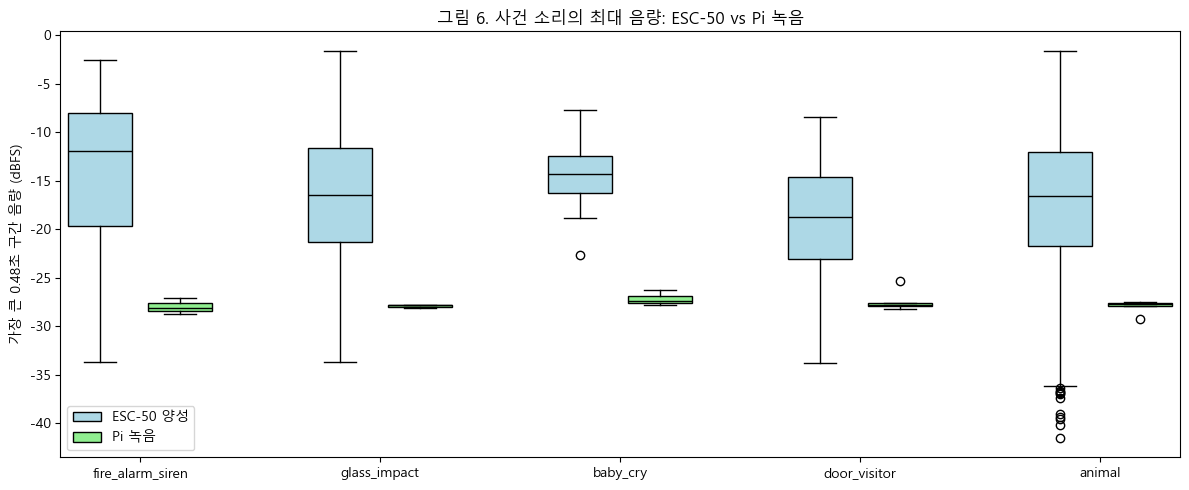

그림 저장: c:\Users\WCL\Documents\GitHub\homecare\yamnet\output\figures\fig6_loudness_gap.png
카테고리별 중앙값 차이(Pi - ESC-50, dB): {'fire_alarm_siren': -16.2, 'glass_impact': -11.4, 'baby_cry': -13.2, 'door_visitor': -9.1, 'animal': -11.1}


In [57]:
esc_level = {}
for c in EVAL_CATS:
    files = esc_meta.loc[ESC_POS[c], "filename"].tolist()
    if files:
        esc_level[c] = [loudest_window_dbfs(sf.read(str(ESC_AUDIO_DIR / f))[0], 44100) for f in files]

fig, ax = plt.subplots(figsize=(12, 5))
cats_lv = [c for c in EVAL_CATS if c in esc_level]
for k, c in enumerate(cats_lv):
    bp1 = ax.boxplot(esc_level[c], positions=[k * 3], widths=0.8, patch_artist=True, boxprops=dict(facecolor="lightblue"), medianprops=dict(color="k"))
    bp2 = ax.boxplot(df.loc[df.category == c, "win_max_dBFS"], positions=[k * 3 + 1], widths=0.8, patch_artist=True,
                     boxprops=dict(facecolor="lightgreen"), medianprops=dict(color="k"))
ax.set_xticks([k * 3 + 0.5 for k in range(len(cats_lv))]); ax.set_xticklabels(cats_lv)
ax.set_ylabel("가장 큰 0.48초 구간 음량 (dBFS)")
ax.legend([bp1["boxes"][0], bp2["boxes"][0]], ["ESC-50 양성", "Pi 녹음"], loc="lower left")
ax.set_title("그림 6. 사건 소리의 최대 음량: ESC-50 vs Pi 녹음")
fig.tight_layout(); savefig(fig, "fig6_loudness_gap.png")
print("카테고리별 중앙값 차이(Pi - ESC-50, dB):",
      {c: round(float(np.median(df.loc[df.category == c, 'win_max_dBFS']) - np.median(esc_level[c])), 1) for c in cats_lv})

### 그림 7. 클래스 구성 변형 비교
변형마다 *ESC-50 오경보 제약 안에서 얻을 수 있는 Pi F-점수*(막대)와 그때의 ESC-50 오경보율(점). ★ = 채택(기본 대비 `MIN_GAIN` 이상 개선).

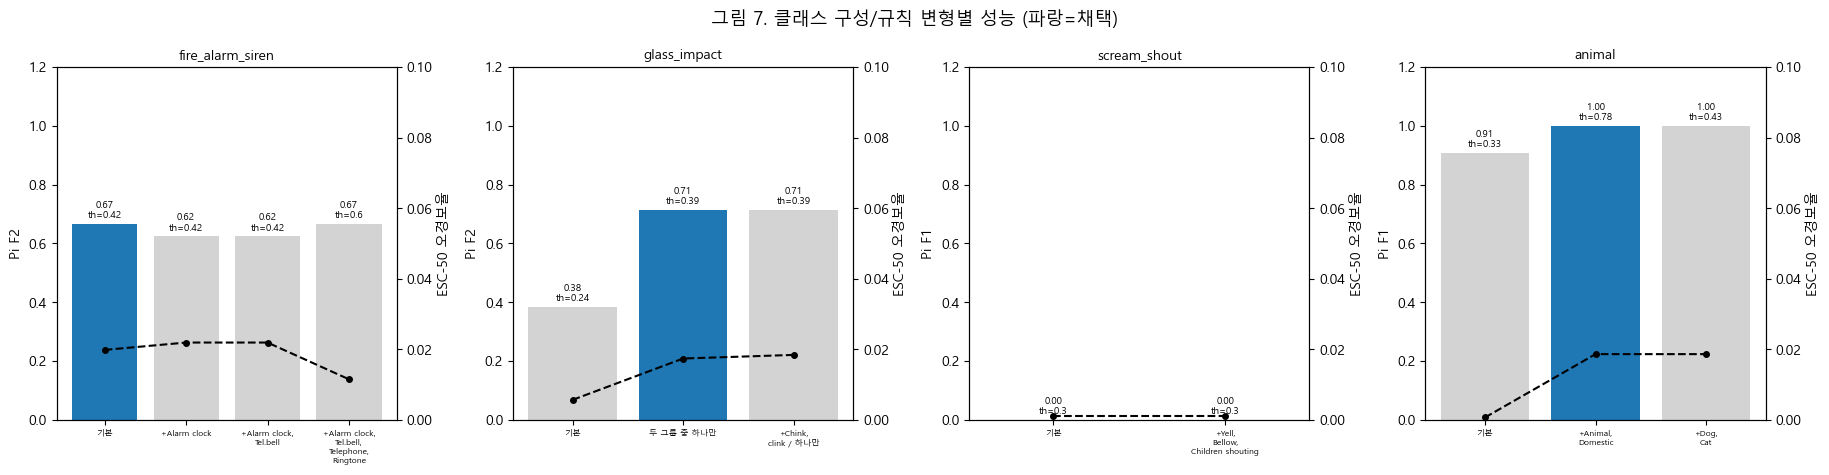

그림 저장: c:\Users\WCL\Documents\GitHub\homecare\yamnet\output\figures\fig7_variant_comparison.png


In [58]:
multi = [c for c in EVAL_CATS if len(VARIANTS[c]) > 1]
fig, axes = plt.subplots(1, len(multi), figsize=(4.6 * len(multi), 4.8))
for ax, c in zip(np.atleast_1d(axes), multi):
    sub = variants_df[variants_df.category == c].reset_index(drop=True)
    colors = ["tab:blue" if str(r.get("채택", "")) == "★" else "lightgray" for _, r in sub.iterrows()]
    ax.bar(range(len(sub)), sub.Pi_score, color=colors)
    for i, r in sub.iterrows():
        ax.text(i, r.Pi_score + 0.02, f"{r.Pi_score:.2f}\nth={r.best_threshold}", ha="center", fontsize=7)
    ax2 = ax.twinx(); ax2.plot(range(len(sub)), sub.ESC50_오경보율, "ko--", ms=4); ax2.set_ylim(0, max(0.1, MAX_ESC_FPR * 2)); ax2.set_ylabel("ESC-50 오경보율")
    ax.set_xticks(range(len(sub))); ax.set_xticklabels([v.replace(",", ",\n") for v in sub.variant], fontsize=6, rotation=0)
    ax.set_ylim(0, 1.2); ax.set_ylabel(f"Pi {METRIC[c]}"); ax.set_title(c, fontsize=10)
fig.suptitle("그림 7. 클래스 구성/규칙 변형별 성능 (파랑=채택)", fontsize=13)
fig.tight_layout(); savefig(fig, "fig7_variant_comparison.png")

### 그림 8. 최종 임계값 요약 표 (이미지)
보고서에 그대로 붙일 수 있는 표. 세부 값은 `realworld_final_thresholds.csv` 에도 저장된다.

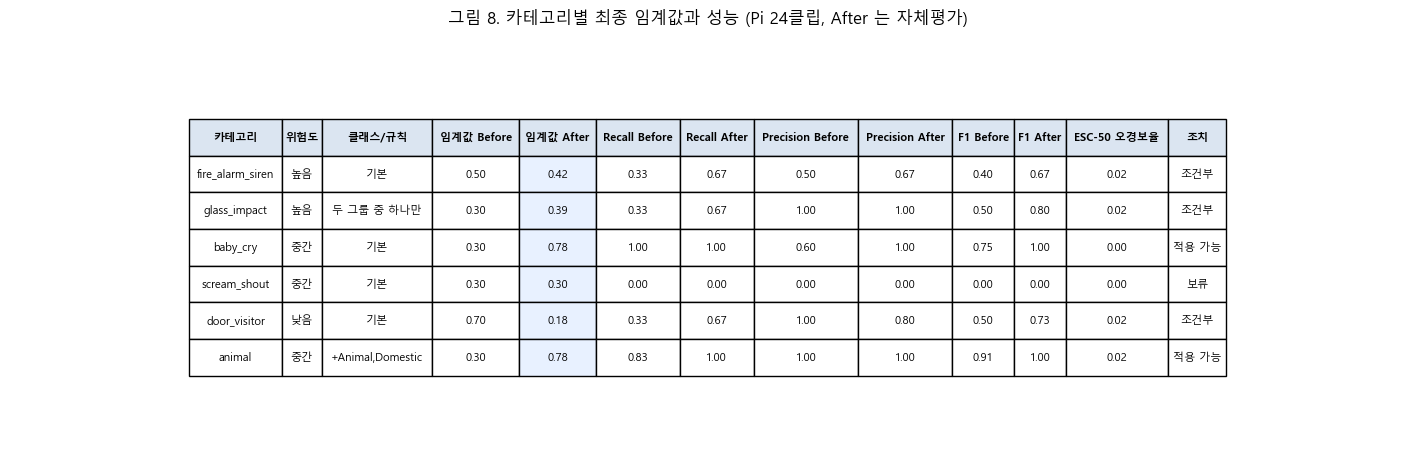

그림 저장: c:\Users\WCL\Documents\GitHub\homecare\yamnet\output\figures\fig8_final_threshold_table.png


In [59]:
show = final_df[["위험도", "클래스/규칙", "임계값 Before", "임계값 After", "Recall Before", "Recall After", "Precision Before",
                 "Precision After", "F1 Before", "F1 After", "ESC-50 오경보율 After", "조치"]].copy()
for col in show.columns:
    if show[col].dtype.kind == "f": show[col] = show[col].map(lambda v: f"{v:.2f}" if pd.notna(v) else "-")
show = show.rename(columns={"ESC-50 오경보율 After": "ESC-50 오경보율"})
show.insert(0, "카테고리", show.index)
fig, ax = plt.subplots(figsize=(18, 0.7 * (len(show) + 2))); ax.axis("off")
tb = ax.table(cellText=show.values, colLabels=show.columns, loc="center", cellLoc="center")
tb.auto_set_font_size(False); tb.set_fontsize(8); tb.auto_set_column_width(list(range(len(show.columns)))); tb.scale(1, 2.2)
for (r, cc), cell in tb.get_celld().items():
    if r == 0: cell.set_facecolor("#dbe5f1"); cell.set_text_props(weight="bold")
    elif show.columns[cc] == "임계값 After": cell.set_facecolor("#e8f1ff")
ax.set_title("그림 8. 카테고리별 최종 임계값과 성능 (Pi 24클립, After 는 자체평가)", fontsize=12)
savefig(fig, "fig8_final_threshold_table.png")

## 10. 음원별 분해 (After 기준)

음원 번호별로 정답 클립을 잡은 비율. 특정 음원만 계속 놓친다면 그 음원이 이상하거나(재생 음량·품질) 우리 규칙이 그 소리 종류에 약하다는 뜻이다.
`position` 이 서로 다른 값으로 기록된 녹음이 생기면 위치별 표도 같이 나온다(지금은 전부 `center` 라 생략).

In [60]:
df["detected_after"] = [bool(PRED_AFTER[df.loc[i, "category"]][i]) for i in range(len(df))]
df["detected_before"] = [bool(PRED_BEFORE[df.loc[i, "category"]][i]) for i in range(len(df))]
for key in [k for k in ["source", "position"] if df[k].nunique() > 1]:
    t = df.groupby(["category", key]).agg(clips=("clip_id", "count"), before=("detected_before", "mean"), after=("detected_after", "mean")).round(2)
    print(f"\n[{key} 별 정답 클립 검출률]"); display(t.unstack(key))


[source 별 정답 클립 검출률]


clips                     before                     after                    
source               1    2    3    4    5      1    2    3    4    5     1    2    3    4    5
category                                                                                       
animal             2.0  2.0  2.0  NaN  NaN    1.0  0.5  1.0  NaN  NaN   1.0  1.0  1.0  NaN  NaN
baby_cry           1.0  1.0  1.0  NaN  NaN    1.0  1.0  1.0  NaN  NaN   1.0  1.0  1.0  NaN  NaN
door_visitor       1.0  2.0  1.0  1.0  1.0    1.0  0.0  1.0  0.0  0.0   1.0  0.5  1.0  1.0  0.0
fire_alarm_siren   1.0  1.0  1.0  NaN  NaN    0.0  1.0  0.0  NaN  NaN   1.0  1.0  0.0  NaN  NaN
glass_impact       1.0  1.0  1.0  NaN  NaN    1.0  0.0  0.0  NaN  NaN   1.0  1.0  0.0  NaN  NaN
scream_shout       1.0  1.0  1.0  NaN  NaN    0.0  0.0  0.0  NaN  NaN   0.0  0.0  0.0  NaN  NaN

## 11. 남은 오류 분석 (After 기준)
`cat_max_score` 는 그 카테고리 클래스들의 프레임 최대 점수. 임계값보다 낮으면 YAMNet 이 못 알아본 것, 높은데 놓쳤으면 규칙(다수결·조합) 때문이다.

In [61]:
def cat_max_score(cat, scores, overrides=None):
    kw = dict(CATEGORY_RULE_CONFIG[cat]["kwargs"]); kw.update(overrides or {})
    ids = kw.get("class_ids") or [i for g in kw["class_id_groups"] for i in g]
    return float(scores[:, ids].max())

err = []
for i, cid in enumerate(PI_IDS):
    for c in EVAL_CATS:
        pred, truth = PRED_AFTER[c][i], TRUTH[c][i]
        if pred != truth:
            err.append(dict(type="FN(놓침)" if truth else "FP(오경보)", clip_id=cid.split("_center")[0], true=df.loc[i, "category"],
                            rule=c, threshold=TH_AFTER[c], cat_max=round(cat_max_score(c, PI_SCORES[cid], VARIANTS[c][FINAL[c]["variant"]]), 3),
                            top_classes=top_classes(PI_SCORES[cid])))
errors = pd.DataFrame(err)
print(f"After 기준 오류 {len(errors)}건 (FN {int(errors.type.str.startswith('FN').sum()) if len(errors) else 0}, "
      f"FP {int(errors.type.str.startswith('FP').sum()) if len(errors) else 0})")
display(errors if len(errors) else "오류 없음")

After 기준 오류 9건 (FN 7, FP 2)


,type,clip_id,true,rule,threshold,cat_max,top_classes
0,FN(놓침),door_visitor2,door_visitor,door_visitor,0.18,0.042,"Music(0.84), Speech(0.55), Buzzer(0.48)"
1,FN(놓침),door_visitor5,door_visitor,door_visitor,0.18,0.011,"Speech(0.89), Arrow(0.17), Heart sounds, heartbeat(0.15)"
2,FN(놓침),fire_alarm_siren3,fire_alarm_siren,fire_alarm_siren,0.42,0.277,"Speech(0.97), Wail, moan(0.69), Music(0.68)"
3,FP(오경보),fire_alarm_siren3,fire_alarm_siren,door_visitor,0.18,0.439,"Speech(0.97), Wail, moan(0.69), Music(0.68)"
4,FN(놓침),glass_impact3,glass_impact,glass_impact,0.39,0.048,"Inside, small room(0.27), Hands(0.16), Finger snapping(0.14)"
5,FN(놓침),scream_shout,scream_shout,scream_shout,0.30,0.414,"Crying, sobbing(0.98), Baby cry, infant cry(0.92), Screaming(0.41)"
6,FN(놓침),scream_shout2,scream_shout,scream_shout,0.30,0.257,"Cricket(0.83), Insect(0.69), Whistling(0.57)"
7,FP(오경보),scream_shout3,scream_shout,fire_alarm_siren,0.42,0.555,"Speech(0.72), Alarm(0.55), Whistle(0.55)"
8,FN(놓침),scream_shout3,scream_shout,scream_shout,0.30,0.029,"Speech(0.72), Alarm(0.55), Whistle(0.55)"


## 12. 결과 저장 + 코드에 반영할 값

`yamnet/output/` 에 저장:
- `realworld_final_thresholds.csv` : 7번 최종 표 (보고서 표)
- `realworld_variant_comparison.csv` : 6번 변형 비교
- `realworld_eval_summary.csv` : Before / After / 교차검증 카테고리별 지표
- `realworld_eval_clips.csv` : 클립별 Before/After 판정
- `figures/fig1~fig8*.png` : 보고서용 그래프

In [62]:
final_df.reset_index().round(4).to_csv(OUTPUT_DIR / "realworld_final_thresholds.csv", index=False, encoding="utf-8-sig")
variants_df.round(4).to_csv(OUTPUT_DIR / "realworld_variant_comparison.csv", index=False, encoding="utf-8-sig")
summary = pd.concat([before.assign(setting="Before(현재)"), after.assign(setting="After(자체평가)"),
                     cvt.assign(setting="교차검증", threshold=np.nan)]).reset_index().round(4)
summary.to_csv(OUTPUT_DIR / "realworld_eval_summary.csv", index=False, encoding="utf-8-sig")
df[["clip_id", "category", "source", "position", "win_max_dBFS", "detected_before", "detected_after"]].round(2).to_csv(
    OUTPUT_DIR / "realworld_eval_clips.csv", index=False, encoding="utf-8-sig")

print("event_rules.py 에 옮겨 적을 값 (사람이 직접 수정 — 이 노트북은 파일을 고치지 않는다)")
print("-" * 78)
for c in EVAL_CATS:
    f = FINAL[c]; ov = VARIANTS[c][f["variant"]]
    extra = f"  클래스/규칙 변경: {f['variant']} -> {ov}" if ov else ""
    print(f"{c:18s} threshold {DEFAULT_TH[c]} -> {f['threshold']}   [{final_df.loc[c, '조치']}]{extra}")
print("-" * 78)
print(f"macro F1  Before {before['F1'].mean():.3f} | After(자체) {after['F1'].mean():.3f} | 교차검증 {cvt['F1'].mean():.3f}")
print(f"macro Recall  Before {before['Recall'].mean():.3f} | After(자체) {after['Recall'].mean():.3f} | 교차검증 {cvt['Recall'].mean():.3f}")

event_rules.py 에 옮겨 적을 값 (사람이 직접 수정 — 이 노트북은 파일을 고치지 않는다)
------------------------------------------------------------------------------
fire_alarm_siren   threshold 0.5 -> 0.42   [조건부]
glass_impact       threshold 0.3 -> 0.39   [조건부]  클래스/규칙 변경: 두 그룹 중 하나만 -> {'min_groups': 1}
baby_cry           threshold 0.3 -> 0.78   [적용 가능]
scream_shout       threshold 0.3 -> 0.3   [보류]
door_visitor       threshold 0.7 -> 0.18   [조건부]
animal             threshold 0.3 -> 0.78   [적용 가능]  클래스/규칙 변경: +Animal,Domestic -> {'class_ids': [70, 78, 67, 68]}
------------------------------------------------------------------------------
macro F1  Before 0.510 | After(자체) 0.699 | 교차검증 0.610
macro Recall  Before 0.472 | After(자체) 0.667 | 교차검증 0.583


## 13. 해석 / 적용 순서 / 다음 단계

**코드에 반영하는 순서**
1. `조치` 가 **적용 가능**인 카테고리부터 `core/event_rules.py` 의 `CATEGORY_RULE_CONFIG` 에서 `threshold`(와 변형이 채택된 경우 클래스 구성)를 직접 수정한다.
2. **조건부/보류**는 값을 바꾸지 말고 해당 클립을 다시 들어보거나 음량·거리를 바꿔 녹음을 보강한 뒤 이 노트북을 다시 실행한다.
3. 반영 후에는 **새로 녹음한 세션**을 `dataset/` 에 넣고 4번 표(= 고정 임계값 평가)를 한 번만 본다. 그 값이 진짜 성능이다.
4. `fire_alarm_siren` 에 전화벨·알람시계 클래스를 넣는 변형을 채택하면, 집 전화/휴대폰 벨소리가 화재 경보로 울릴 수 있다. ESC-50 에는 벨소리 음원이 없어 이 위험은 *검증되지 않는다* → 생활소음 배경 녹음으로 확인 후 채택.

**보고서에 쓰는 법**
- "Pi 마이크 24클립 기준 macro F1 ○○(Before) → ○○(교차검증)". 반드시 *표본이 작고 1세션이라 신뢰구간이 넓다*를 같이 쓴다.
- 그림 1(튜닝 곡선), 그림 2(전/후 비교), 그림 5·6(도메인 갭 증거), 그림 8(최종 표)이 핵심이다.

**아직 모르는 것 → 다음 녹음**
1. 사건 없는 배경 녹음 2~3시간 (FA/h, 진짜 특이도).
2. 다른 날·시간대의 새 세션 (최종 test).
3. 위치(left/right)와 음량을 **기록하면서** 녹음 (`record_dataset.py ... left`, `--note "음량=작게"`) — 지금은 기록이 없어 분석 불가.
4. 같은 음원을 음량만 바꿔 녹음한 쌍 (음량이 점수를 얼마나 바꾸는지 직접 측정).